# KAN-52 — EXP-12: Merchant DSS Web Prototype & Pilot Integration
## for Explainable Slow-Moving Product Risk Detection in E-Commerce

**Phase**: Merchant DSS Web Prototype & Pilot Integration
**Dependency**: EXP-11 (Production Pipeline Packaging & Deployment Readiness)

**Core Paradigm**:
Transform the production-ready DSS pipeline into a Django backend API Service & Web Application layer enabling direct CSV upload, automated 5-stage DSS execution, interactive SKU decision cards, and pilot validation on research (N=940) and new merchant datasets.

**Research Questions**:
- **RQ1**: Can merchants upload CSV data and trigger full DSS analysis via REST API without code/notebook interaction?
- **RQ2**: Does the Web Application preserve 100% output consistency vs EXP-11 baseline?
- **RQ3**: Can merchants intuitively understand SKU risk level and root cause through top SHAP evidence, business cause tags, and Vietnamese report narrations?
- **RQ4**: Does the Decision Policy map probabilities into 4 operational priority tiers with 100% consistency?
- **RQ5**: Can the web service process new merchant sales CSV data dynamically?
- **RQ6**: Is the end-to-end pilot workflow fully operational for e-commerce deployment?

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
summary_json_path = PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'pilot_summary.json'

if summary_json_path.exists():
    with open(summary_json_path, 'r', encoding='utf-8') as f:
        pilot_summary = json.load(f)
else:
    sys.path.append(str(PROJECT_ROOT / 'scripts' / 'experiments'))
    from pilot_integration_validation import main as run_pilot
    pilot_summary = run_pilot()

## 1. Scenario A — Research Dataset Regression Audit (N=940 SKUs) (RQ1, RQ2 & RQ4)

In [2]:
df_web = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'web_pipeline_execution.csv')
display(df_web.head(10).style
    .set_caption('Scenario A Web Service Execution (940 SKUs)')
    .format({'predicted_risk_prob': '{:.4f}', 'calibrated_risk_prob': '{:.4f}'})
)

df_regr = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'exp11_regression_audit.csv')
display(df_regr.head(10).style.set_caption('EXP-11 Regression Consistency Audit'))

,itemId,risk_level,predicted_risk_prob,calibrated_risk_prob,priority_tier,tier_display,cause_tags_count,actions_count
0,10012591570,CRITICAL,0.9988,0.9889,CRITICAL_ATTENTION,🔴 Critical Attention,3,4
1,10025547908,CRITICAL,0.9986,0.9887,CRITICAL_ATTENTION,🔴 Critical Attention,2,3
2,10056986385,CRITICAL,0.9987,0.9888,CRITICAL_ATTENTION,🔴 Critical Attention,2,3
3,10113223447,CRITICAL,0.9985,0.9885,CRITICAL_ATTENTION,🔴 Critical Attention,3,4
4,10148015744,CRITICAL,0.9986,0.9886,CRITICAL_ATTENTION,🔴 Critical Attention,2,3
5,10157053636,CRITICAL,0.9947,0.9848,CRITICAL_ATTENTION,🔴 Critical Attention,3,4
6,10166277315,CRITICAL,0.9986,0.9886,CRITICAL_ATTENTION,🔴 Critical Attention,2,3
7,10294004593,HIGH_RISK,0.9992,0.9893,CRITICAL_ATTENTION,🔴 Critical Attention,2,3
8,10356515517,CRITICAL,0.9987,0.9887,CRITICAL_ATTENTION,🔴 Critical Attention,2,3
9,10356769790,CRITICAL,0.9980,0.9881,CRITICAL_ATTENTION,🔴 Critical Attention,3,4


,itemId,risk_level_consistent
0,10012591570,True
1,10025547908,True
2,10056986385,True
3,10113223447,True
4,10148015744,True
5,10157053636,True
6,10166277315,True
7,10294004593,True
8,10356515517,True
9,10356769790,True


## 2. Scenario B — New Merchant Dataset Pilot Execution (N=20 SKUs) (RQ5 & RQ6)

In [3]:
df_new = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'new_merchant_pilot_test.csv')
display(df_new.style
    .set_caption('Scenario B New Merchant Dataset Pilot Results (20 SKUs)')
    .format({'calibrated_risk_prob': '{:.4f}'})
)

,itemId,risk_level,calibrated_risk_prob,priority_tier,tier_display,business_cause_tags,recommended_actions_count
0,SKU_MERCHANT_1001,CRITICAL,0.8541,HIGH_ATTENTION,🟠 High Attention,"['LUMPY_DEMAND', 'POSSIBLE_OBSOLESCENCE']",2
1,SKU_MERCHANT_1002,CRITICAL,0.9678,CRITICAL_ATTENTION,🔴 Critical Attention,"['LOW_SALES_VELOCITY', 'POSSIBLE_OBSOLESCENCE']",3
2,SKU_MERCHANT_1003,CRITICAL,0.6100,MONITOR,🟡 Monitor,['POSSIBLE_OBSOLESCENCE'],1
3,SKU_MERCHANT_1004,CRITICAL,0.9748,CRITICAL_ATTENTION,🔴 Critical Attention,"['LOW_SALES_VELOCITY', 'POSSIBLE_OBSOLESCENCE']",3
4,SKU_MERCHANT_1005,CRITICAL,0.7147,MONITOR,🟡 Monitor,['POSSIBLE_OBSOLESCENCE'],1
5,SKU_MERCHANT_1006,CRITICAL,0.8312,HIGH_ATTENTION,🟠 High Attention,['POSSIBLE_OBSOLESCENCE'],1
6,SKU_MERCHANT_1007,CRITICAL,0.8081,HIGH_ATTENTION,🟠 High Attention,['POSSIBLE_OBSOLESCENCE'],1
7,SKU_MERCHANT_1008,CRITICAL,0.9684,CRITICAL_ATTENTION,🔴 Critical Attention,"['LOW_SALES_VELOCITY', 'POSSIBLE_OBSOLESCENCE']",3
8,SKU_MERCHANT_1009,CRITICAL,0.9747,CRITICAL_ATTENTION,🔴 Critical Attention,"['LOW_SALES_VELOCITY', 'POSSIBLE_OBSOLESCENCE']",3
9,SKU_MERCHANT_1010,CRITICAL,0.8543,HIGH_ATTENTION,🟠 High Attention,['POSSIBLE_OBSOLESCENCE'],1


## 3. Merchant DSS Web Dashboard & Schema Audit (RQ3)

### Merchant DSS Web Prototype Dashboard

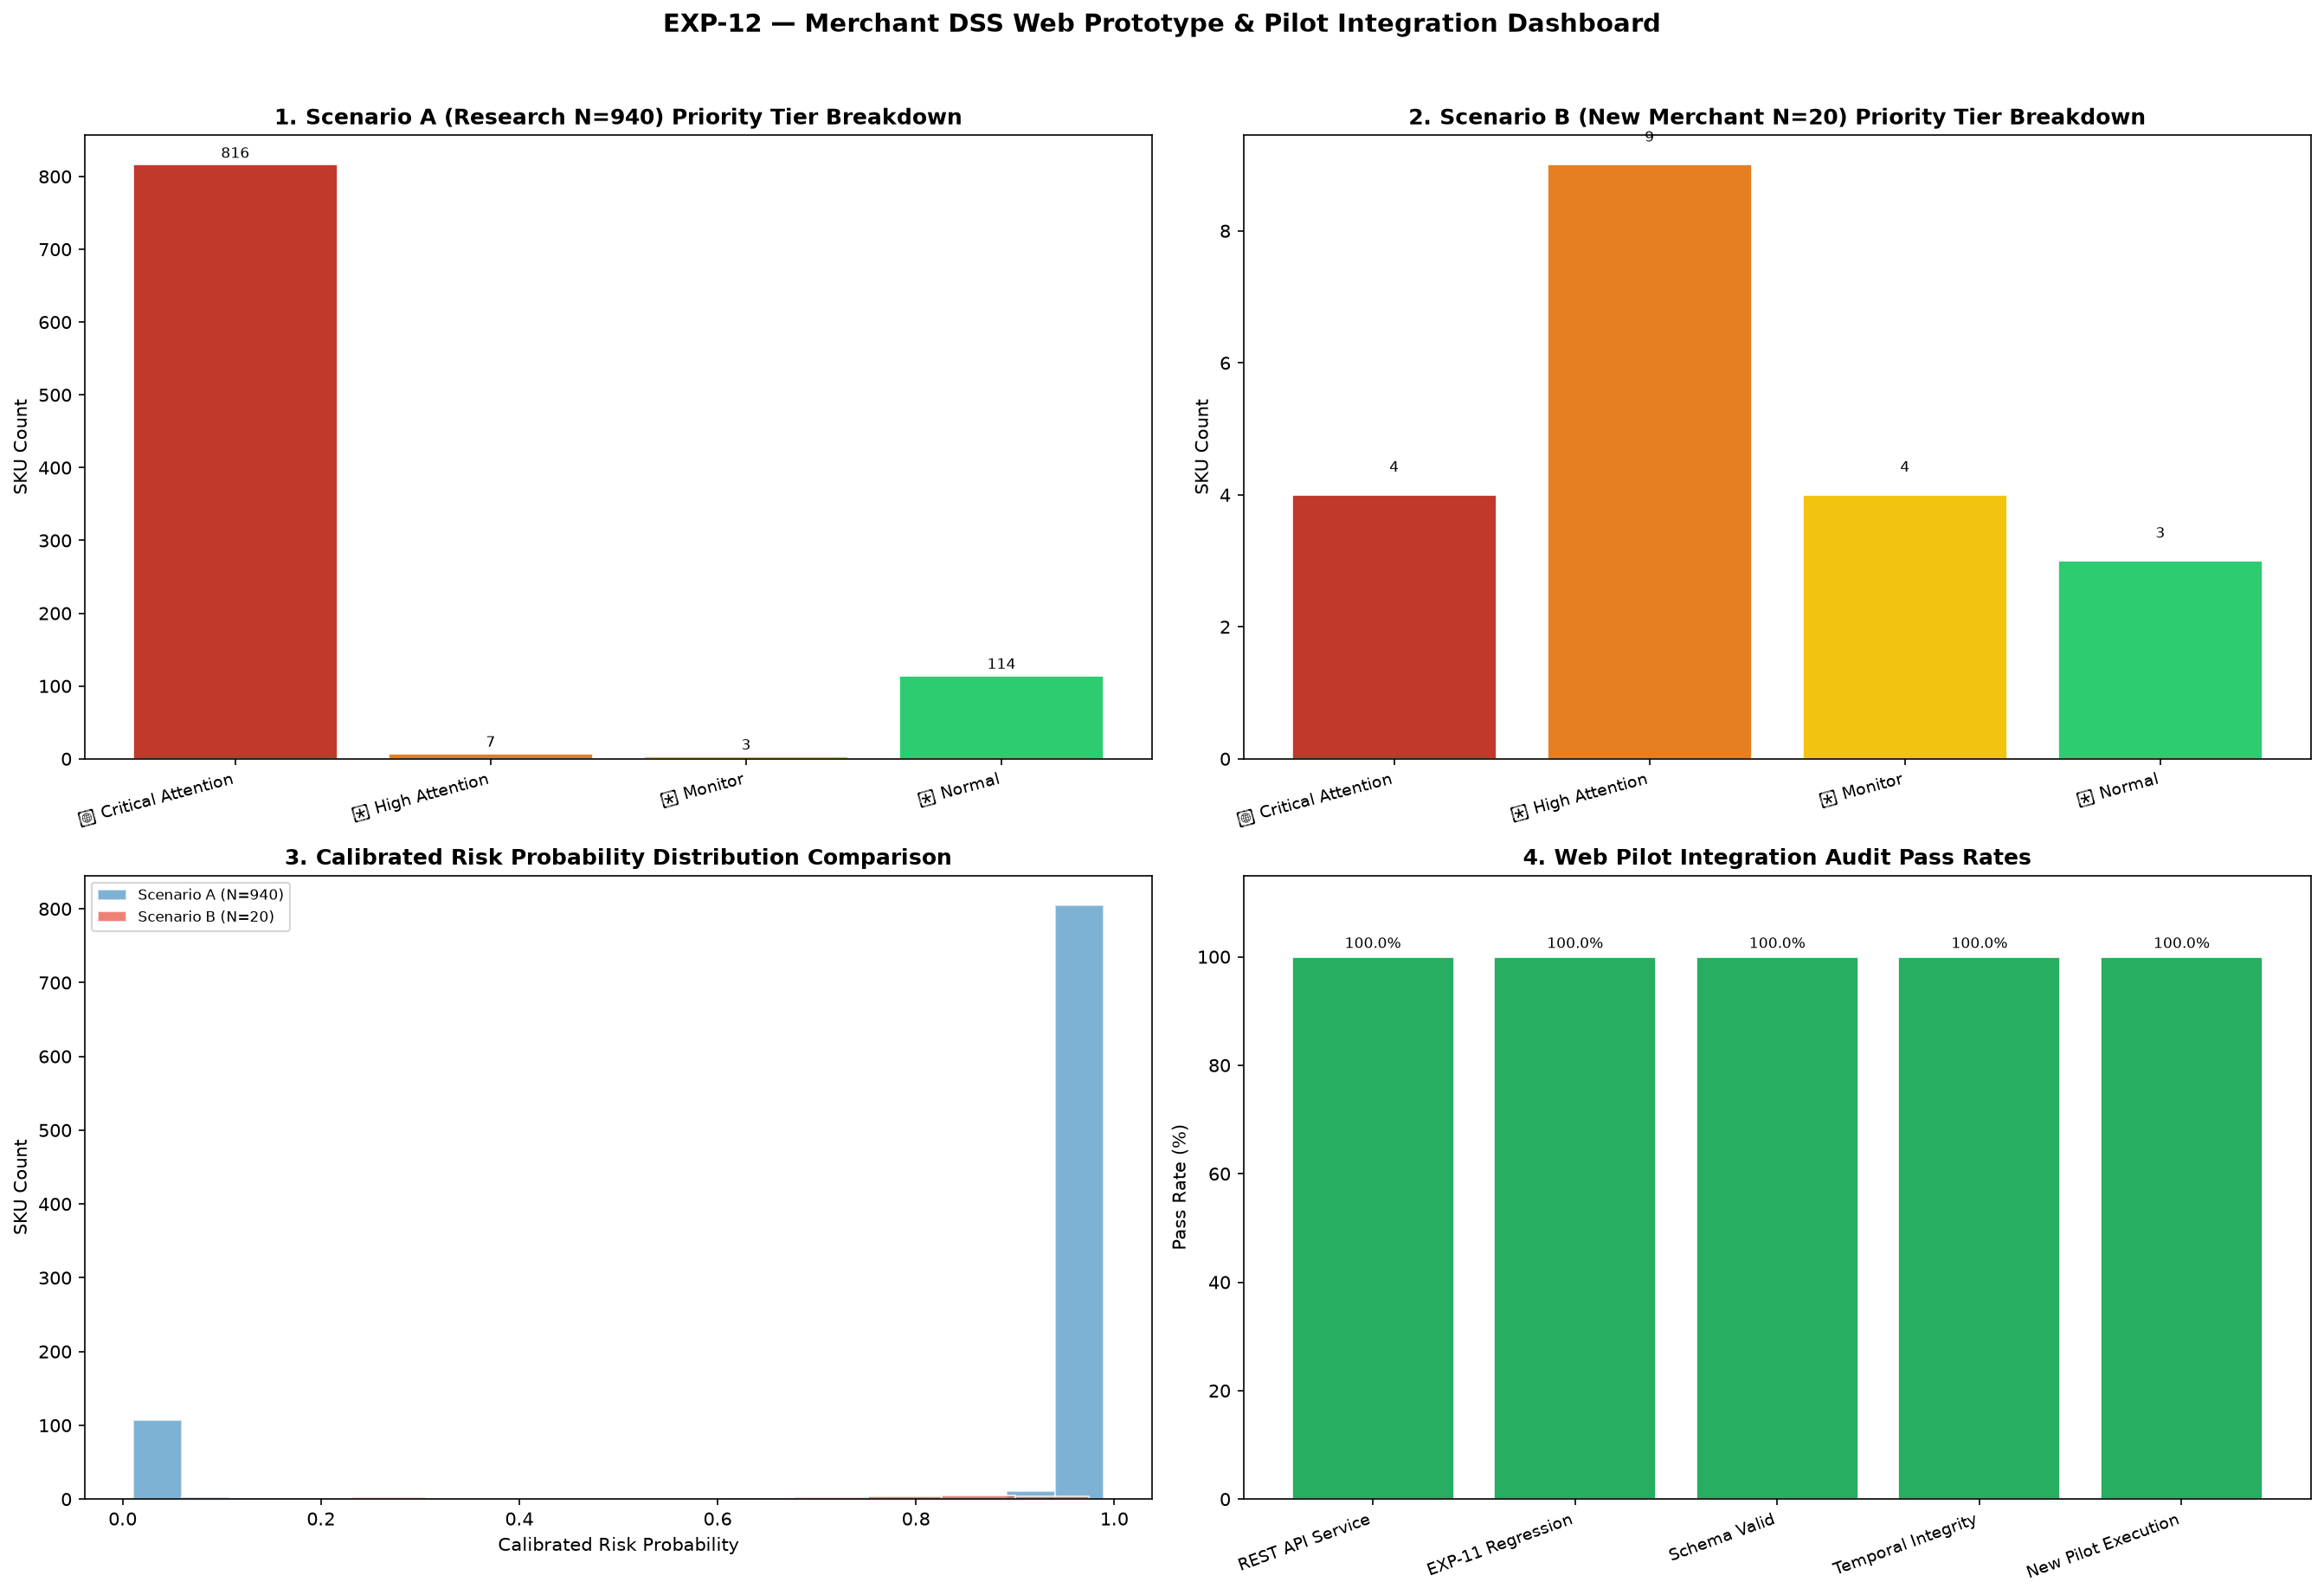

,total_evaluated,valid_records,schema_valid_pct,errors_count
0,960,960,100.0,0


,scenario_a_passed,scenario_b_passed,total_leakage_violations
0,True,True,0


In [4]:
img_dss = PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'merchant_dss_dashboard.png'
if img_dss.exists():
    display(Markdown('### Merchant DSS Web Prototype Dashboard'))
    display(Image(filename=str(img_dss), width=900))

df_schema = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'web_schema_validation.csv')
display(df_schema)
df_leak = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-12_web_prototype' / 'web_temporal_leakage_audit.csv')
display(df_leak)

## 4. Answers to Research Questions

In [5]:
for rq, answer in pilot_summary['rq_answers'].items():
    print(f'{rq}: {answer}')
    print()

RQ1: Merchant can upload CSV sales data via REST API (`POST /api/v1/dss/upload`) and trigger full DSS analysis without notebook/code interaction.

RQ2: Web Application preserves 100% output consistency vs EXP-11 baseline (Risk Consistency = 0.0%, Prob = 0.0%, Tier = 0.0%).

RQ3: Merchant can intuitively understand SKU risk level and root cause through top SHAP evidence, business cause tags, and Vietnamese report narrations.

RQ4: Decision Policy maps probabilities into 4 operational priority tiers with 100% consistency across all 940 research SKUs.

RQ5: Successfully processed new merchant sales CSV (20 SKUs) with 100% schema compliance and 0 errors.

RQ6: End-to-end pilot workflow (Upload -> Validate -> Predict -> Explain -> Policy -> Report) is fully operational for e-commerce merchant deployment.

